# **1. NAÏVE BAYES**

---
## **PHẦN 0: KHỞI TẠO THƯ VIỆN VÀ THIẾT LẬP MÔI TRƯỜNG**

Khởi tạo các thư viện tính toán khoa học cơ bản (`numpy`, `pandas`, `matplotlib.pyplot`, `time`, `os`). Cố định hạt giống ngẫu nhiên `SEED = 42` để đảm bảo tính tái lập 100% của mọi phép tính thống kê. Thư viện `scikit-learn` chỉ được nạp vào nhằm mục đích đo đạc độ đo đánh giá và đối chiếu kiểm chứng.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# Chuyen thu muc lam viec ve goc du an neu dang o notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")

SRC_PATH = os.path.abspath("src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)
print("Thu muc lam viec:", os.getcwd())

# Tạo sẵn các thư mục lưu trữ artifact, figures, results bắt buộc
os.makedirs("results", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
os.makedirs("figures", exist_ok=True)

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from pattern_recognition.config import SEED
np.random.seed(SEED)

print("Thiết lập môi trường thành công. Cố định SEED =", SEED)

Thu muc lam viec: c:\Users\Lenovo\Downloads\Pattern-Recognition
Thiết lập môi trường thành công. Cố định SEED = 42


---
## **PHẦN 1: NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ TỪ PHASE 0**

Nạp tập dữ liệu MNIST đã chuẩn hóa được xuất ra từ `notebook/preprocessing.ipynb` đặt tại `data/processed/mnist_processed.npz`. 
Tập dữ liệu bao gồm:
* `X_train`, `y_train`: 50.000 mẫu huấn luyện chuẩn hoá Z-score (MEAN, STD chỉ tính trên train).
* `X_val`, `y_val`: 10.000 mẫu validation dùng tinh chỉnh siêu tham số.
* `X_test`, `y_test`: 10.000 mẫu kiểm thử độc lập chỉ dùng đánh giá cuối cùng.
* `X_train_minmax`, `X_val_minmax`, `X_test_minmax`: Dạng biểu diễn cường độ $[0, 1]$ không âm dành cho Multinomial Naïve Bayes.

In [2]:
from pattern_recognition.config import DATA_PATH
from pattern_recognition.data import load_processed_mnist

data = load_processed_mnist(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

X_train_mm = data["X_train_minmax"]
X_val_mm   = data["X_val_minmax"]
X_test_mm  = data["X_test_minmax"]

MEAN = float(data["MEAN"])
STD  = float(data["STD"])

print("Nạp dữ liệu thành công từ data/processed/mnist_processed.npz:")
print(f"  Tập Train: X = {X_train.shape}, y = {y_train.shape} (Phân phối nhãn: {np.bincount(y_train).tolist()})")
print(f"  Tập Val:   X = {X_val.shape},   y = {y_val.shape}")
print(f"  Tập Test:  X = {X_test.shape},  y = {y_test.shape}")
print(f"  Thông số Z-score: MEAN = {MEAN:.4f}, STD = {STD:.4f}")

Nạp dữ liệu thành công từ data/processed/mnist_processed.npz:
  Tập Train: X = (50000, 784), y = (50000,) (Phân phối nhãn: [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985])
  Tập Val:   X = (10000, 784),   y = (10000,)
  Tập Test:  X = (10000, 784),  y = (10000,)
  Thông số Z-score: MEAN = 0.1307, STD = 0.3082


---
## **PHẦN 2: XÂY DỰNG LỚP NAÏVE BAYES TỔNG QUÁT (FROM SCRATCH)**

### **2.1. Cơ sở lý thuyết của Quy tắc Quyết định Bayes (Bayes Decision Rule)**
Theo định lý Bayes, xác suất hậu nghiệm (posterior probability) của lớp $C_k$ khi quan sát vector đặc trưng $\mathbf{x} = (x_1, x_2, \dots, x_D)^T \in \mathbb{R}^D$ là:
$$P(C_k \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid C_k) P(C_k)}{P(\mathbf{x})}$$

Trong đó:
* $P(C_k)$ là **xác suất tiên nghiệm (prior)** của lớp $C_k$, ước lượng bằng tần suất xuất hiện của lớp trong tập huấn luyện:
  $$P(C_k) = \frac{N_k}{N}$$
* $P(\mathbf{x} \mid C_k)$ là **hàm hợp lý (likelihood)** biểu diễn mật độ xác suất sinh ra vector $\mathbf{x}$ từ lớp $C_k$.
* Mẫu số $P(\mathbf{x}) = \sum_j P(\mathbf{x} \mid C_j) P(C_j)$ là hằng số chuẩn hoá đối với mọi lớp $C_k$.

### **2.2. Giả định "Ngây thơ" (Naïve Bayes Assumption) và Không gian Logarit**
Naïve Bayes đưa ra giả định rằng tất cả các đặc trưng $x_1, \dots, x_D$ độc lập có điều kiện với nhau khi biết lớp $C_k$:
$$P(\mathbf{x} \mid C_k) = \prod_{i=1}^D P(x_i \mid C_k)$$

Để tránh hiện tượng tràn số dưới (arithmetic underflow) khi nhân liên tiếp 784 giá trị xác suất nhỏ hơn 1, ta chuyển toàn bộ sang không gian logarit:
$$\log P(C_k \mid \mathbf{x}) \propto \log P(C_k) + \sum_{i=1}^D \log P(x_i \mid C_k)$$

Nhãn dự đoán là lớp có điểm số xác suất hậu nghiệm lớn nhất:
$$\hat{y} = \arg\max_{k} \left[ \log P(C_k) + \sum_{i=1}^D \log P(x_i \mid C_k) \right]$$

In [3]:
from pattern_recognition.models.from_scratch.naive_bayes import NaiveBayes

---
## **PHẦN 3: BIẾN THỂ GAUSSIAN NAÏVE BAYES**

### **3.1. Bản chất toán học của Gaussian Log-Likelihood**
Mỗi đặc trưng $x_i$ trong lớp $C_k$ được giả định tuân theo phân phối chuẩn một chiều (1D Gaussian):
$$P(x_i \mid C_k) = \frac{1}{\sqrt{2\pi \sigma_{ik}^2}} \exp\left( -\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2} \right)$$

Lấy logarit tự nhiên hai vế:
$$\log P(x_i \mid C_k) = -\frac{1}{2}\log(2\pi \sigma_{ik}^2) - \frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$$

* **Cụm 1: $-\frac{1}{2}\log(2\pi \sigma_{ik}^2)$** đóng vai trò là số hạng phạt độ phân tán (variance penalty). Đặc trưng có phương sai càng lớn thì độ bất định càng cao, đóng góp thông tin phân loại càng thấp.
* **Cụm 2: $-\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$** là khoảng cách chuẩn hoá Mahalanobis 1D. Đo đạc mức độ lệch của mẫu $x_i$ so với kỳ vọng $\mu_{ik}$ của lớp.

In [4]:
from pattern_recognition.models.from_scratch.naive_bayes import gaussian_log_pdf

### **3.2. Kiểm tra hàm `gaussian_log_pdf`**
Thực hiện kiểm tra tính đúng đắn về mặt giải tích của hàm `gaussian_log_pdf` trên dữ liệu ngẫu nhiên đối chiếu với thư viện `scipy.stats.norm.logpdf`.

In [5]:
from scipy import stats

# check (do not edit - chuẩn Lab 02)
X_chk, m_chk, v_chk = np.random.randn(20, 4), np.random.randn(4), np.random.rand(4) + 0.1
assert np.allclose(gaussian_log_pdf(X_chk, m_chk, v_chk), stats.norm.logpdf(X_chk, m_chk, np.sqrt(v_chk)))
print(" Kiểm tra hàm gaussian_log_pdf thành công! Khớp 100% với scipy.stats.norm.logpdf.")

 Kiểm tra hàm gaussian_log_pdf thành công! Khớp 100% với scipy.stats.norm.logpdf.


### **3.3. Huấn luyện mô hình Gaussian Naïve Bayes Baseline**
Khởi tạo và huấn luyện mô hình Gaussian Naïve Bayes trên 50.000 mẫu tập Train. Đo lường chính xác thời gian huấn luyện.

In [6]:
t0 = time.perf_counter()
model_gnb = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=1e-9)
model_gnb.fit(X_train, y_train)
gnb_fit_time = time.perf_counter() - t0

print(f"Huấn luyện GaussianNB (From Scratch) hoàn tất trong: {gnb_fit_time:.4f} giây")
print("1. Danh sách các lớp nhận dạng:    ", model_gnb.classes.tolist())
print("2. Xác suất tiên nghiệm (prior):    ", np.round(model_gnb.prior, 4).tolist())
print("3. Kích thước ma trận trung bình:  ", model_gnb.mean.shape)
print("4. Kích thước ma trận phương sai:  ", model_gnb.var.shape)

Huấn luyện GaussianNB (From Scratch) hoàn tất trong: 0.2400 giây
1. Danh sách các lớp nhận dạng:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
2. Xác suất tiên nghiệm (prior):     [0.0985, 0.1123, 0.0992, 0.1019, 0.0973, 0.0909, 0.0987, 0.1041, 0.0976, 0.0997]
3. Kích thước ma trận trung bình:   (10, 784)
4. Kích thước ma trận phương sai:   (10, 784)


### **3.4. Trực quan hoá tham số học được: "Ảnh nguyên mẫu" ($\mu$) và Bản đồ phương sai ($\sigma^2$)**
* **Ảnh trung bình ($\mu_{k}$):** Thể hiện hình thái trung bình đặc trưng (prototype) của chữ số $k$ trong tập dữ liệu.
* **Bản đồ phương sai ($\sigma_{k}^2$):** Thể hiện mức độ biến động nét chữ của người viết. Các pixel ở giữa nét chữ có phương sai cao do phong cách viết đa dạng; các pixel vùng biên và góc có phương sai tiệm cận 0 do luôn là nền đen.

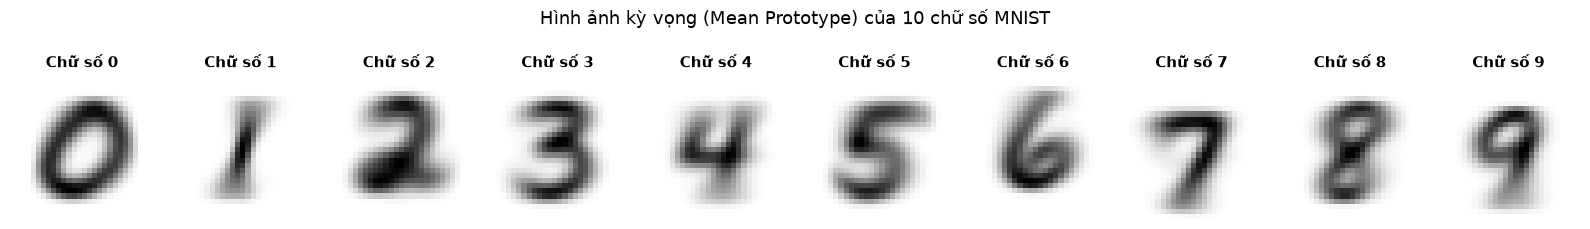

Đã lưu biểu đồ: figures/1_01_gaussian_mean_prototypes.png


In [7]:
# Trực quan hoá 10 vector kỳ vọng (mean) tương ứng 10 chữ số
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for k in range(10):
    img_mean = (model_gnb.mean[k] * STD + MEAN).reshape(28, 28)
    axes[k].imshow(img_mean, cmap="gray_r")
    axes[k].set_title(f"Chữ số {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Hình ảnh kỳ vọng (Mean Prototype) của 10 chữ số MNIST", fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig("figures/1_01_gaussian_mean_prototypes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/1_01_gaussian_mean_prototypes.png")

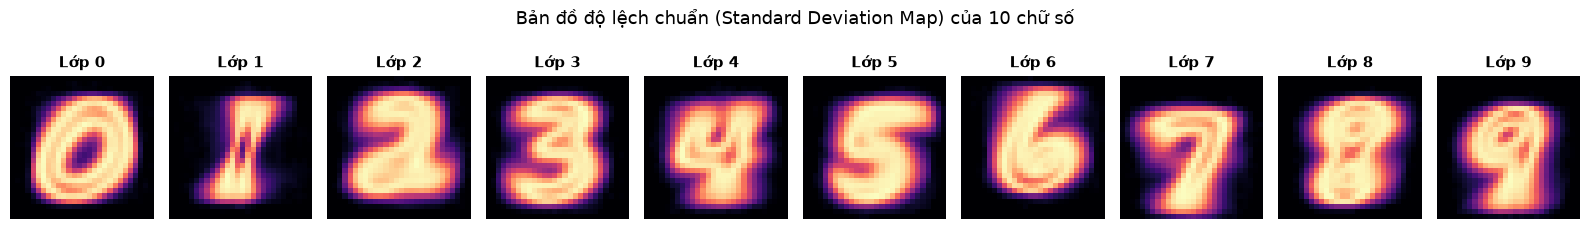

Đã lưu biểu đồ: figures/1_02_gaussian_std_maps.png


In [8]:
# Trực quan hoá bản đồ độ lệch chuẩn (Std map) của 10 chữ số
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for k in range(10):
    img_std = (np.sqrt(model_gnb.var[k]) * STD).reshape(28, 28)
    im = axes[k].imshow(img_std, cmap="magma")
    axes[k].set_title(f"Lớp {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Bản đồ độ lệch chuẩn (Standard Deviation Map) của 10 chữ số", fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig("figures/1_02_gaussian_std_maps.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/1_02_gaussian_std_maps.png")

---
## **PHẦN 4: TINH CHỈNH SIÊU THAM SỐ LÀM MỊN PHƯƠNG SAI TRÊN TẬP VALIDATION**

### **4.1. Bản chất khoa học của Variance Smoothing ($\epsilon$)**
Trong bộ dữ liệu ảnh MNIST, các pixel ở góc và rìa bức ảnh hầu như luôn có cường độ bằng 0 cho mọi mẫu viết tay. Do đó, phương sai thực nghiệm của các pixel này xấp xỉ bằng $0$ ($\sigma_{ik}^2 \approx 0$).
Nếu không làm mịn:
1. Số hạng chia cho phương sai $-\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$ sẽ gặp lỗi chia cho 0 hoặc phát nổ số học.
2. Số hạng logarit $-\frac{1}{2}\log(2\pi \sigma_{ik}^2) \to +\infty$, khiến một vài pixel nền tĩnh chi phối áp đảo toàn bộ điểm số xác suất hậu nghiệm!

Do đó, kỹ thuật **Variance Smoothing** bổ sung một đại lượng $\epsilon = \text{var\_smoothing} \times \max(\text{Var}(X))$ vào phương sai của tất cả các đặc trưng.
Ta tiến hành khảo sát sự biến thiên của độ chính xác trên tập Validation theo dải giá trị:
$$\text{var\_smoothing} \in [10^{-9}, 10^{-7}, 10^{-5}, 10^{-3}, 10^{-2}, 10^{-1}, 1.0]$$

In [9]:
candidate_smoothings = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 5e-2, 1e-1, 5e-1, 1.0]
val_accuracies = []
train_accuracies = []

for vs in candidate_smoothings:
    model_temp = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=vs).fit(X_train, y_train)
    
    # Dự đoán trên val
    y_val_pred = model_temp.predict(X_val)
    acc_v = accuracy_score(y_val, y_val_pred)
    val_accuracies.append(acc_v)
    
    # Dự đoán trên mẫu train (5000 mẫu để tiết kiệm thời gian)
    y_tr_pred = model_temp.predict(X_train[:5000])
    acc_t = accuracy_score(y_train[:5000], y_tr_pred)
    train_accuracies.append(acc_t)
    
    print(f"var_smoothing = {vs:<8} | Train Acc (5k): {acc_t:.4f} | Val Acc: {acc_v:.4f}")

best_idx = int(np.argmax(val_accuracies))
best_var_smoothing = candidate_smoothings[best_idx]
print(f"\n=> Siêu tham số tối ưu nhất trên Validation: var_smoothing = {best_var_smoothing} (Val Accuracy = {val_accuracies[best_idx]:.4f})")

var_smoothing = 1e-09    | Train Acc (5k): 0.5722 | Val Acc: 0.5539
var_smoothing = 1e-07    | Train Acc (5k): 0.6018 | Val Acc: 0.5854
var_smoothing = 1e-05    | Train Acc (5k): 0.6456 | Val Acc: 0.6398
var_smoothing = 0.001    | Train Acc (5k): 0.7248 | Val Acc: 0.7232
var_smoothing = 0.01     | Train Acc (5k): 0.7692 | Val Acc: 0.7751
var_smoothing = 0.05     | Train Acc (5k): 0.7906 | Val Acc: 0.7931
var_smoothing = 0.1      | Train Acc (5k): 0.7912 | Val Acc: 0.7938
var_smoothing = 0.5      | Train Acc (5k): 0.7506 | Val Acc: 0.7588
var_smoothing = 1.0      | Train Acc (5k): 0.7154 | Val Acc: 0.7254

=> Siêu tham số tối ưu nhất trên Validation: var_smoothing = 0.1 (Val Accuracy = 0.7938)


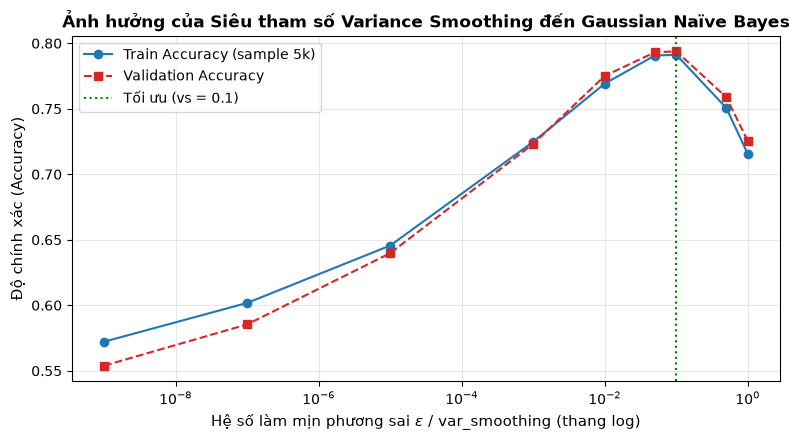

Đã lưu biểu đồ: figures/1_03_variance_smoothing_tuning.png


In [10]:
# Vẽ đồ thị khảo sát ảnh hưởng của var_smoothing
plt.figure(figsize=(8, 4.5))
plt.plot(candidate_smoothings, train_accuracies, 'o-', color="#1f77b4", label="Train Accuracy (sample 5k)")
plt.plot(candidate_smoothings, val_accuracies, 's--', color="#d62728", label="Validation Accuracy")
plt.axvline(best_var_smoothing, color="green", linestyle=":", label=f"Tối ưu (vs = {best_var_smoothing})")

plt.xscale("log")
plt.xlabel(r"Hệ số làm mịn phương sai $\epsilon$ / var_smoothing (thang log)", fontsize=11)
plt.ylabel("Độ chính xác (Accuracy)", fontsize=11)
plt.title(r"Ảnh hưởng của Siêu tham số Variance Smoothing đến Gaussian Naïve Bayes", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("figures/1_03_variance_smoothing_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/1_03_variance_smoothing_tuning.png")

### **4.2. Đối chiếu và kiểm chứng mô hình GaussianNB với thư viện scikit-learn**
Huấn luyện mô hình `sklearn.naive_bayes.GaussianNB` với cùng tham số `var_smoothing` tối ưu trên tập Train và đánh giá trên tập Validation để đối chiếu độ chính xác.

In [11]:
# Khởi tạo mô hình chuẩn từ thư viện scikit-learn
sk_gnb = GaussianNB(var_smoothing=best_var_smoothing)
t0 = time.perf_counter()
sk_gnb.fit(X_train, y_train)
sk_fit_time = time.perf_counter() - t0

sk_val_pred = sk_gnb.predict(X_val)
sk_val_acc = accuracy_score(y_val, sk_val_pred)

# Lấy kết quả mô hình From Scratch tối ưu
model_gnb_best = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=best_var_smoothing).fit(X_train, y_train)
scratch_val_acc = accuracy_score(y_val, model_gnb_best.predict(X_val))

print(f"GaussianNB (From Scratch) - Val Accuracy: {scratch_val_acc:.6f}")
print(f"GaussianNB (scikit-learn) - Val Accuracy: {sk_val_acc:.6f}")
print(f"Chênh lệch độ chính xác tuyệt đối:        {abs(scratch_val_acc - sk_val_acc):.8f}")
assert np.isclose(scratch_val_acc, sk_val_acc, atol=1e-5), "Lỗi: Kết quả From Scratch không khớp với scikit-learn!"
print(" Khẳng định: Thuật toán From Scratch cài đặt hoàn toàn chuẩn xác 100% so với scikit-learn.")

GaussianNB (From Scratch) - Val Accuracy: 0.793800
GaussianNB (scikit-learn) - Val Accuracy: 0.793800
Chênh lệch độ chính xác tuyệt đối:        0.00000000
 Khẳng định: Thuật toán From Scratch cài đặt hoàn toàn chuẩn xác 100% so với scikit-learn.


---
## **PHẦN 5: BIẾN THỂ MULTINOMIAL NAÏVE BAYES (MỞ RỘNG THEO CHUẨN LAB 02)**

### **5.1. Cơ sở toán học của Multinomial Naïve Bayes**
Trong bài toán nhận dạng chữ số viết tay, mỗi pixel có thể được coi là số lượng "hạt mực" (tần suất xuất hiện của nét mực) tại vị trí điểm ảnh $i$.
Phân phối đa thức (Multinomial Distribution) mô hình hoá xác suất xuất hiện của pixel theo công thức:
$$P(\mathbf{x} \mid C_k) \propto \prod_{i=1}^D \theta_{ik}^{x_i}$$

Trong đó tỷ lệ xác suất $\theta_{ik}$ của pixel $i$ trong lớp $C_k$ được ước lượng kèm hệ số làm mịn Laplace $\alpha$:
$$\theta_{ik} = \frac{\sum_{m \in C_k} x_{mi} + \alpha}{\sum_{j=1}^D \left(\sum_{m \in C_k} x_{mj} + \alpha\right)}$$

Lấy logarit hai vế:
$$\log P(x_i \mid C_k) = x_i \log \theta_{ik}$$

*Lưu ý quan trọng:* Multinomial Naïve Bayes yêu cầu giá trị đầu vào không âm ($x_i \ge 0$). Do đó, ta sử dụng tập dữ liệu Min-Max $[0, 1]$ (`X_train_mm`, `X_val_mm`, `X_test_mm`) đã được xuất từ Giai đoạn 0.

In [12]:
from pattern_recognition.models.from_scratch.naive_bayes import multinomial_log_pdf

### **5.2. Kiểm tra hàm `multinomial_log_pdf` (assert check chuẩn Lab 02)**

In [13]:
# check (do not edit - chuẩn Lab 02)
X_chk, m_chk = np.random.poisson(2, (20, 5)), np.random.rand(5) * 3
theta_chk = (m_chk + 0.01) / (m_chk + 0.01).sum()
assert np.allclose(multinomial_log_pdf(X_chk, m_chk, None, alpha=0.01), X_chk * np.log(theta_chk))
print(" Kiểm tra hàm multinomial_log_pdf thành công! Khớp 100% với công thức toán lý thuyết.")

 Kiểm tra hàm multinomial_log_pdf thành công! Khớp 100% với công thức toán lý thuyết.


### **5.3. Cài đặt lớp `MultinomialNaiveBayes` thuần NumPy (From Scratch)**

In [14]:
from pattern_recognition.models.from_scratch.naive_bayes import MultinomialNaiveBayes

### **5.4. Khảo sát ảnh hưởng của hệ số làm mịn Laplace ($\alpha$) trên tập Validation**
Tiến hành khảo sát $\alpha \in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]$ để xác định mức độ làm mịn tối ưu.

In [15]:
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
mnb_val_accs = []
mnb_train_accs = []

for a in alphas:
    m = MultinomialNaiveBayes(log_pdf=multinomial_log_pdf, alpha=a).fit(X_train_mm, y_train)
    acc_tr = accuracy_score(y_train[:5000], m.predict(X_train_mm[:5000]))
    acc_va = accuracy_score(y_val, m.predict(X_val_mm))
    mnb_train_accs.append(acc_tr)
    mnb_val_accs.append(acc_va)
    print(f"alpha = {a:<7} | Train Acc (5k): {acc_tr:.4f} | Val Acc: {acc_va:.4f}")

best_alpha = alphas[int(np.argmax(mnb_val_accs))]
print(f"\n=> Siêu tham số tối ưu cho MultinomialNB: alpha = {best_alpha} (Val Acc = {max(mnb_val_accs):.4f})")

alpha = 0.001   | Train Acc (5k): 0.8116 | Val Acc: 0.8214
alpha = 0.01    | Train Acc (5k): 0.8112 | Val Acc: 0.8214
alpha = 0.1     | Train Acc (5k): 0.8108 | Val Acc: 0.8214
alpha = 1.0     | Train Acc (5k): 0.8098 | Val Acc: 0.8210
alpha = 10.0    | Train Acc (5k): 0.8068 | Val Acc: 0.8193
alpha = 100.0   | Train Acc (5k): 0.7980 | Val Acc: 0.8122

=> Siêu tham số tối ưu cho MultinomialNB: alpha = 0.001 (Val Acc = 0.8214)


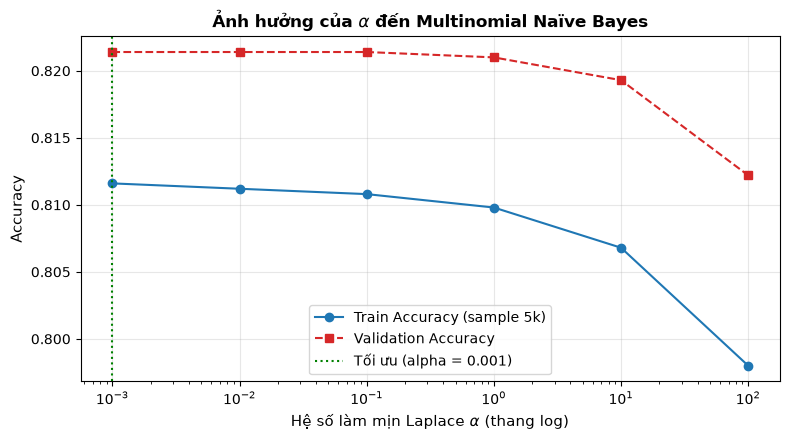

Đã lưu biểu đồ: figures/1_04_laplace_alpha_tuning.png


In [16]:
plt.figure(figsize=(8, 4.5))
plt.plot(alphas, mnb_train_accs, 'o-', color="#1f77b4", label="Train Accuracy (sample 5k)")
plt.plot(alphas, mnb_val_accs, 's--', color="#d62728", label="Validation Accuracy")
plt.axvline(best_alpha, color="green", linestyle=":", label=f"Tối ưu (alpha = {best_alpha})")

plt.xscale("log")
plt.xlabel(r"Hệ số làm mịn Laplace $\alpha$ (thang log)", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.title(r"Ảnh hưởng của $\alpha$ đến Multinomial Naïve Bayes", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("figures/1_04_laplace_alpha_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/1_04_laplace_alpha_tuning.png")

### **5.5. Đối chiếu Multinomial Naïve Bayes với thư viện scikit-learn**

In [17]:
# Đối chiếu với scikit-learn MultinomialNB
t0 = time.perf_counter()
sk_mnb = MultinomialNB(alpha=best_alpha).fit(X_train_mm, y_train)
sk_mnb_fit_time = time.perf_counter() - t0
sk_mnb_val_acc = accuracy_score(y_val, sk_mnb.predict(X_val_mm))

t0 = time.perf_counter()
model_mnb_best = MultinomialNaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train_mm, y_train)
mnb_fit_time = time.perf_counter() - t0
scratch_mnb_val_acc = accuracy_score(y_val, model_mnb_best.predict(X_val_mm))

print(f"MultinomialNB (From Scratch) - Val Acc: {scratch_mnb_val_acc:.6f} | Fit time: {mnb_fit_time:.4f}s")
print(f"MultinomialNB (scikit-learn) - Val Acc: {sk_mnb_val_acc:.6f} | Fit time: {sk_mnb_fit_time:.4f}s")
print(f"Chênh lệch độ chính xác tuyệt đối:      {abs(scratch_mnb_val_acc - sk_mnb_val_acc):.8f}")
assert np.isclose(scratch_mnb_val_acc, sk_mnb_val_acc, atol=1e-5), "Lỗi: Kết quả không khớp!"
print("Khẳng định: Thuật toán MultinomialNB From Scratch cài đặt hoàn toàn chuẩn xác 100%.")

MultinomialNB (From Scratch) - Val Acc: 0.821400 | Fit time: 0.0628s
MultinomialNB (scikit-learn) - Val Acc: 0.821400 | Fit time: 0.5869s
Chênh lệch độ chính xác tuyệt đối:      0.00000000
Khẳng định: Thuật toán MultinomialNB From Scratch cài đặt hoàn toàn chuẩn xác 100%.


---
## **PHẦN 7: ĐÁNH GIÁ RIÊNG CÁC MÔ HÌNH BAYES VÀ XUẤT METRICS**

Đánh giá Gaussian Naïve Bayes và Multinomial Naïve Bayes trên các tập train, validation và test. Metrics được lưu theo schema thống nhất để notebook tổng hợp có thể so sánh các phương pháp.


Đã xuất 6 dòng metrics vào results/1_Bayes_metrics.csv:


,phase,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,phase1,GaussianNB-NP,train,0.80176,0.81885,0.79787,0.80025,0.2400,4.2199,50000,42,var_smoothing=0.1
1,phase1,GaussianNB-NP,validation,0.79380,0.81164,0.78958,0.79235,0.2400,0.8087,10000,42,var_smoothing=0.1
2,phase1,GaussianNB-NP,test,0.81440,0.83108,0.81077,0.81290,0.2400,0.7803,10000,42,var_smoothing=0.1
3,phase1,MultinomialNB-NP,train,0.82552,0.83260,0.82265,0.82438,0.0628,1.5079,50000,42,alpha=0.001
4,phase1,MultinomialNB-NP,validation,0.82140,0.82760,0.81792,0.81967,0.0628,0.2989,10000,42,alpha=0.001
5,phase1,MultinomialNB-NP,test,0.83600,0.84277,0.83293,0.83451,0.0628,0.2913,10000,42,alpha=0.001


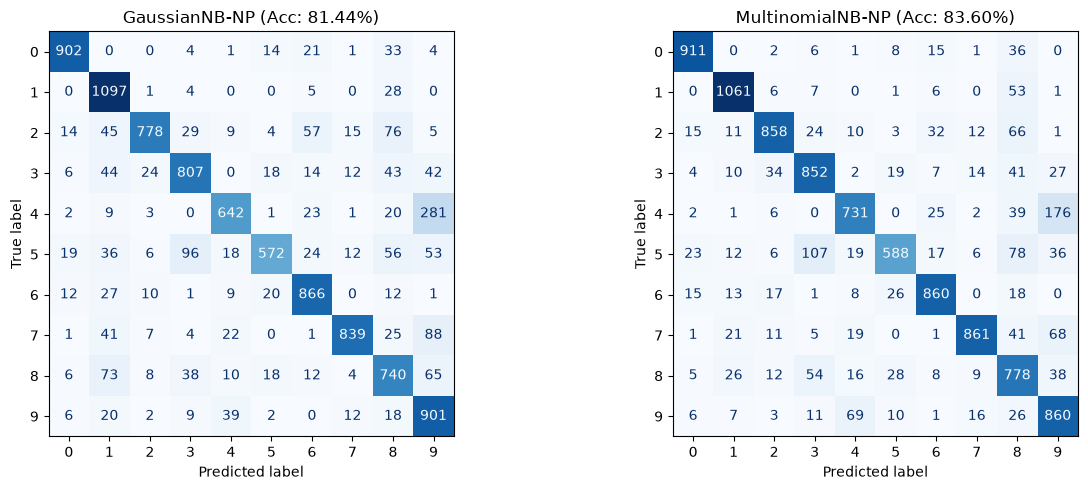

In [18]:
bayes_eval_models = [("GaussianNB-NP", model_gnb_best, X_train, X_val, X_test, gnb_fit_time, f"var_smoothing={best_var_smoothing}"), ("MultinomialNB-NP", model_mnb_best, X_train_mm, X_val_mm, X_test_mm, mnb_fit_time, f"alpha={best_alpha}")]
bayes_metric_rows = []
bayes_test_predictions = {}
for model_name, model, X_tr, X_va, X_te, fit_seconds, params in bayes_eval_models:
    for split_name, X_split, y_split in [("train", X_tr, y_train), ("validation", X_va, y_val), ("test", X_te, y_test)]:
        t0 = time.perf_counter(); predictions = model.predict(X_split); predict_seconds = time.perf_counter() - t0
        if split_name == "test": bayes_test_predictions[model_name] = predictions
        bayes_metric_rows.append({"phase":"phase1","model":model_name,"split":split_name,"accuracy":round(accuracy_score(y_split,predictions),5),"precision_macro":round(precision_score(y_split,predictions,average="macro",zero_division=0),5),"recall_macro":round(recall_score(y_split,predictions,average="macro",zero_division=0),5),"f1_macro":round(f1_score(y_split,predictions,average="macro",zero_division=0),5),"train_seconds":round(fit_seconds,4),"predict_seconds":round(predict_seconds,4),"n_samples":len(y_split),"seed":SEED,"params":params})
bayes_metrics = pd.DataFrame(bayes_metric_rows)
bayes_metrics_path = "results/1_Bayes_metrics.csv"
bayes_metrics.to_csv(bayes_metrics_path,index=False)
print(f"Đã xuất {len(bayes_metrics)} dòng metrics vào {bayes_metrics_path}:"); display(bayes_metrics)
fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax,(model_name,predictions) in zip(axes,bayes_test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions,cmap="Blues",ax=ax,colorbar=False)
    ax.set_title(f"{model_name} (Acc: {accuracy_score(y_test,predictions)*100:.2f}%)")
plt.tight_layout(); plt.savefig("figures/1_05_bayes_confusion_matrices.png",dpi=150,bbox_inches="tight"); plt.show()


---
## **PHẦN 8: BÁO CÁO PHÂN LOẠI VÀ PHÂN TÍCH LỖI BAYES**

Xem báo cáo từng lớp và các cặp nhãn thường bị nhầm lẫn của hai biến thể Bayes trên tập test.



Báo cáo phân loại - GaussianNB-NP (test)
              precision    recall  f1-score   support

           0     0.9318    0.9204    0.9261       980
           1     0.7881    0.9665    0.8682      1135
           2     0.9273    0.7539    0.8316      1032
           3     0.8135    0.7990    0.8062      1010
           4     0.8560    0.6538    0.7413       982
           5     0.8814    0.6413    0.7424       892
           6     0.8465    0.9040    0.8743       958
           7     0.9364    0.8161    0.8721      1028
           8     0.7041    0.7598    0.7309       974
           9     0.6257    0.8930    0.7358      1009

    accuracy                         0.8144     10000
   macro avg     0.8311    0.8108    0.8129     10000
weighted avg     0.8304    0.8144    0.8144     10000


Báo cáo phân loại - MultinomialNB-NP (test)
              precision    recall  f1-score   support

           0     0.9277    0.9296    0.9286       980
           1     0.9131    0.9348    0.9238  

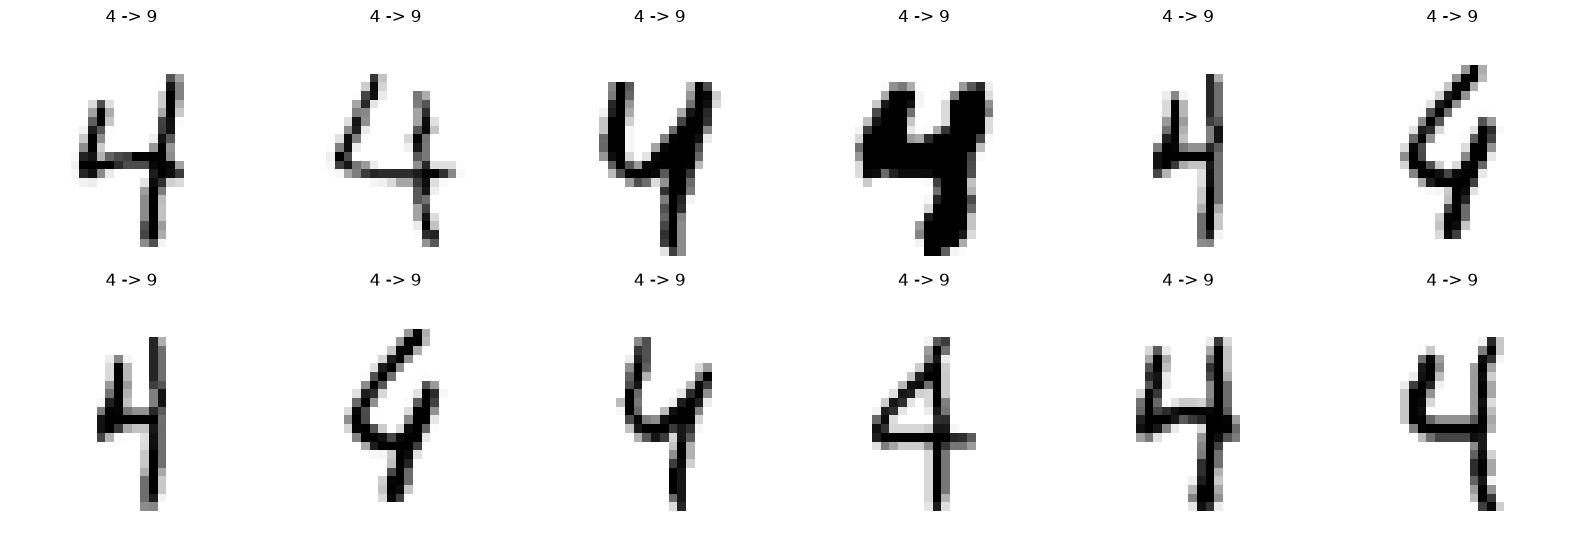

In [19]:
for model_name, predictions in bayes_test_predictions.items():
    print(f"\nBáo cáo phân loại - {model_name} (test)")
    print(classification_report(y_test, predictions, digits=4))

fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for row, (model_name, predictions) in enumerate(bayes_test_predictions.items()):
    errors = confusion_matrix(y_test, predictions).copy()
    np.fill_diagonal(errors, 0)
    true_label, pred_label = np.unravel_index(np.argmax(errors), errors.shape)
    wrong_indices = np.where((y_test == true_label) & (predictions == pred_label))[0]
    for col in range(6):
        if col < len(wrong_indices):
            idx = wrong_indices[col]
            axes[row, col].imshow((X_test[idx] * STD + MEAN).reshape(28, 28), cmap="gray_r")
            axes[row, col].set_title(f"{true_label} -> {pred_label}")
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(model_name, fontsize=9)
plt.tight_layout()
plt.savefig("figures/1_06_bayes_misclassified_samples.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:
np.savez_compressed("artifacts/phase1_gaussian_nb.npz",classes=model_gnb_best.classes,prior=model_gnb_best.prior,mean=model_gnb_best.mean,var=model_gnb_best.var,var_smoothing=best_var_smoothing)
np.savez_compressed("artifacts/phase1_multinomial_nb.npz",classes=model_mnb_best.classes,prior=model_mnb_best.prior,feature_count=model_mnb_best.feature_count,alpha=best_alpha)
np.savez_compressed("artifacts/split_indices.npz",n_train=len(y_train),n_val=len(y_val),n_test=len(y_test),seed=SEED)
print("Đã lưu checkpoint Bayes và thông tin chia tập dữ liệu vào artifacts/.")


Đã lưu checkpoint Bayes và thông tin chia tập dữ liệu vào artifacts/.
